# 03 · Entrenamiento de modelos

Escalera de comparación sobre **validación** (la prueba no se mira):

1. *Baselines* `DummyClassifier` (clase mayoritaria y estratificado).
2. **SVM lineal** con TF-IDF de palabras y caracteres (configuración de partida: la mejor de la Semana 3, C = 0,3).
3. **XLM-RoBERTa** con ajuste fino y parada temprana por F1-macro de validación (requiere GPU).

Regla del proyecto (Semana 4): XLM-R solo reemplaza a la SVM si la supera con McNemar (α = 0,05); ante un empate se queda la SVM, porque es más explicable y liviana.

In [1]:
# Preparación del entorno. En Colab, el repositorio vive en Google Drive para que los 5 notebooks compartan
# datos, modelos y resultados entre sesiones.
import os, sys, json, time, platform, shutil
EN_COLAB = "google.colab" in sys.modules
REPO = "github.com/jobedon/triajeia-isp.git"   # repositorio privado
if EN_COLAB:
    from google.colab import drive, userdata
    drive.mount("/content/drive")
    DESTINO = "/content/drive/MyDrive/triajeia-isp"
    ZIP = "/content/drive/MyDrive/triajeia-isp.zip"
    try:
        TOKEN = userdata.get("GITHUB_TOKEN")      # Secretos de Colab (🔑): token de solo lectura
    except Exception:
        TOKEN = None
    if TOKEN:
        url = f"https://x-access-token:{TOKEN}@{REPO}"
        if not os.path.exists(f"{DESTINO}/.git"):
            r = os.system(f"git clone -q {url} {DESTINO} > /dev/null 2>&1")
        else:
            r = os.system(f"git -C {DESTINO} pull -q {url} main > /dev/null 2>&1")
        print("Código actualizado desde GitHub" if r == 0 else "No se pudo usar GitHub; se usa la copia de Drive")
    elif not os.path.exists(DESTINO) and os.path.exists(ZIP):
        shutil.unpack_archive(ZIP, "/content/drive/MyDrive")
        print("Código extraído de triajeia-isp.zip")
    if not os.path.exists(f"{DESTINO}/config.yaml"):
        raise FileNotFoundError("No se encontró el código. Agregue el secreto GITHUB_TOKEN o suba triajeia-isp.zip a la raíz de Drive.")
    os.chdir(DESTINO)
    os.system('pip install -q "scikit-learn==1.6.1" "optuna>=4" "fairlearn>=0.12"')
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
PRUEBA_RAPIDA = os.environ.get("PRUEBA_RAPIDA", "0") == "1"   # solo para verificar el código; sus números no se usan
print("Directorio:", os.getcwd(), "| Colab:", EN_COLAB, "| Prueba rápida:", PRUEBA_RAPIDA)

Mounted at /content/drive
Código actualizado desde GitHub
Directorio: /content/drive/MyDrive/triajeia-isp | Colab: True | Prueba rápida: False


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from src.utils import cargar_config, cargar_json, fijar_semilla, guardar_json

cfg = cargar_config()
SEMILLA = cfg["semilla"]
fijar_semilla(SEMILLA)
FIG, MET = "results/figures", "results/metrics"
os.makedirs(FIG, exist_ok=True); os.makedirs(MET, exist_ok=True); os.makedirs("models", exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
GRANATE = "#791632"

def guardar_fig(nombre):
    plt.tight_layout()
    plt.savefig(f"{FIG}/{nombre}.png", dpi=150, bbox_inches="tight")
    plt.show()

def entorno():
    e = {"colab": EN_COLAB, "prueba_rapida": PRUEBA_RAPIDA, "python": platform.python_version(),
         "sklearn": sklearn.__version__, "pandas": pd.__version__, "fecha": time.strftime("%Y-%m-%d %H:%M")}
    try:
        import torch
        e["torch"] = torch.__version__
        e["gpu"] = torch.cuda.get_device_name(0) if torch.cuda.is_available() else None
    except ImportError:
        e["gpu"] = None
    return e
NB = "03"

In [3]:
from sklearn.dummy import DummyClassifier
from src.evaluate import ic_bootstrap, mcnemar, metricas
from src.model import ClasificadorTriaje, construir_svm
P = cfg["datos"]["procesados"]
train, val, test = (pd.read_csv(f"{P}/{n}.csv") for n in ("train", "val", "test"))
OBJ = cfg["datos"]["objetivos"]
print(len(train), len(val), len(test))

1105 195 200


## 1. Baselines y SVM

In [4]:
res = {o: {} for o in OBJ}
pred_val = {o: {} for o in OBJ}
for o in OBJ:
    for nombre, est in [("dummy_mayoritaria", DummyClassifier(strategy="most_frequent")),
                        ("dummy_estratificado", DummyClassifier(strategy="stratified", random_state=SEMILLA))]:
        p = est.fit(train["texto"], train[o]).predict(val["texto"])
        pred_val[o][nombre] = p; res[o][nombre] = metricas(val[o], p)
    svm = construir_svm(cfg["svm"], SEMILLA).fit(train["texto"], train[o])
    p = svm.predict(val["texto"]); pred_val[o]["svm"] = p; res[o]["svm"] = metricas(val[o], p)
    res[o]["svm"]["f1_macro_train"] = metricas(train[o], svm.predict(train["texto"]))["f1_macro"]
    res[o]["svm"]["ic_val"] = ic_bootstrap(val[o], p, n=cfg["evaluacion"]["bootstrap"])
    if o == "categoria": svm_cat = svm
    else: svm_pri = svm
tabla = pd.DataFrame({(o, m): {"F1-macro val": r["f1_macro"], "exactitud val": r["exactitud"]}
                      for o in OBJ for m, r in res[o].items()}).T.round(3)
tabla

F1-macro val  exactitud val
categoria dummy_mayoritaria           0.029          0.169
          dummy_estratificado         0.093          0.113
          svm                         0.996          0.995
prioridad dummy_mayoritaria           0.189          0.395
          dummy_estratificado         0.340          0.379
          svm                         0.863          0.851

In [5]:
for o in OBJ:
    r = res[o]["svm"]
    print(f"{o}: F1 train {r['f1_macro_train']:.3f} · F1 val {r['f1_macro']:.3f} · "
          f"brecha {r['f1_macro_train'] - r['f1_macro']:.3f} · IC95 val [{r['ic_val'][1]:.3f}; {r['ic_val'][2]:.3f}]")
v1 = ClasificadorTriaje({"categoria": svm_cat, "prioridad": svm_pri}, cfg["areas"], cfg["decision"]["umbral_confianza"],
                        metadatos={"version": "v1_svm_base", "params": cfg["svm"], "entrenado_con": "train"})
v1.guardar("models/model_v1_svm_base.joblib")

categoria: F1 train 1.000 · F1 val 0.996 · brecha 0.004 · IC95 val [0.986; 1.000]
prioridad: F1 train 0.998 · F1 val 0.863 · brecha 0.135 · IC95 val [0.812; 0.909]


19:57:15 | INFO | src.model | Modelo guardado en /content/drive/MyDrive/triajeia-isp/models/model_v1_svm_base.joblib
INFO:src.model:Modelo guardado en /content/drive/MyDrive/triajeia-isp/models/model_v1_svm_base.joblib


PosixPath('/content/drive/MyDrive/triajeia-isp/models/model_v1_svm_base.joblib')

La brecha entre entrenamiento y validación indica cuánto memoriza la SVM (en la Semana 3 fue *varianza alta*). Se revisa de nuevo en `04_optimizacion` con validación cruzada.

## 2. XLM-RoBERTa (GPU)

Se entrena una vez por objetivo con la configuración de `config.yaml`. Se guardan sus probabilidades sobre validación y **sobre la prueba sin mirarlas**: se abrirán una sola vez en `05_evaluacion` para la comparación final con McNemar.

In [6]:
import importlib.util
HAY_TORCH = importlib.util.find_spec("torch") is not None
if HAY_TORCH:
    import torch
    from torch.utils.data import DataLoader
    from transformers import AutoModelForSequenceClassification, AutoTokenizer, get_linear_schedule_with_warmup
    from sklearn.metrics import f1_score

    def entrenar_xlmr(tr, va, extra, objetivo, p, epocas_max, paciencia, semilla=SEMILLA):
        """Ajuste fino de XLM-R con parada temprana por F1-macro de validación (lección de la Semana 3).
        Devuelve historia por época, predicciones de validación y de «extra» con el mejor estado."""
        fijar_semilla(semilla)
        clases = sorted(tr[objetivo].unique()); idx = {c: i for i, c in enumerate(clases)}
        tok = AutoTokenizer.from_pretrained(p["modelo"])
        modelo = AutoModelForSequenceClassification.from_pretrained(
            p["modelo"], num_labels=len(clases), hidden_dropout_prob=p["dropout"], attention_probs_dropout_prob=p["dropout"]).cuda()
        def lotes(d, barajar):
            enc = tok(list(d["texto"]), truncation=True, max_length=p["max_len"], padding=True, return_tensors="pt")
            y = torch.tensor([idx.get(c, 0) for c in d[objetivo]])
            ds = torch.utils.data.TensorDataset(enc["input_ids"], enc["attention_mask"], y)
            return DataLoader(ds, batch_size=p["lote"], shuffle=barajar)
        dl_tr, dl_va = lotes(tr, True), lotes(va, False)
        opt = torch.optim.AdamW(modelo.parameters(), lr=p["lr"], weight_decay=p["weight_decay"])
        pasos = len(dl_tr) * epocas_max
        sch = get_linear_schedule_with_warmup(opt, int(0.1 * pasos), pasos)
        scaler = torch.amp.GradScaler()
        def predecir(dl):
            modelo.eval(); out = []
            with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
                for ids, am, _ in dl:
                    out.append(torch.softmax(modelo(input_ids=ids.cuda(), attention_mask=am.cuda()).logits.float(), -1).cpu())
            return torch.cat(out).numpy()
        historia, mejor, sin_mejora, mejor_estado = [], -1, 0, None
        for ep in range(1, epocas_max + 1):
            modelo.train(); perdida = 0
            for ids, am, y in dl_tr:
                opt.zero_grad()
                with torch.autocast("cuda", dtype=torch.float16):
                    loss = modelo(input_ids=ids.cuda(), attention_mask=am.cuda(), labels=y.cuda()).loss
                scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sch.step(); perdida += loss.item()
            pv = predecir(dl_va)
            f1v = f1_score(va[objetivo], [clases[i] for i in pv.argmax(1)], average="macro", zero_division=0)
            historia.append({"epoca": ep, "loss_train": perdida / len(dl_tr), "f1_val": f1v})
            print(f"  época {ep}: loss {perdida / len(dl_tr):.3f} · F1 val {f1v:.3f}")
            if f1v > mejor:
                mejor, sin_mejora = f1v, 0
                mejor_estado = {k: v.detach().cpu().clone() for k, v in modelo.state_dict().items()}
            else:
                sin_mejora += 1
                if sin_mejora >= paciencia:
                    break
        modelo.load_state_dict(mejor_estado)
        res = {"clases": clases, "historia": historia, "mejor_f1_val": mejor,
               "mejor_epoca": max(historia, key=lambda h: h["f1_val"])["epoca"],
               "proba_val": predecir(dl_va).tolist()}
        for nombre, d in extra.items():
            res[f"proba_{nombre}"] = predecir(lotes(d, False)).tolist()
        del modelo; torch.cuda.empty_cache()
        return res

In [7]:
EJECUTAR_XLMR = HAY_TORCH and not PRUEBA_RAPIDA and __import__("torch").cuda.is_available()
xlmr = {}
if EJECUTAR_XLMR:
    for o in OBJ:
        print("XLM-R ·", o)
        t0 = time.time()
        xlmr[o] = entrenar_xlmr(train, val, {"test": test}, o, cfg["xlmr"], cfg["xlmr"]["epocas_max"], cfg["xlmr"]["paciencia"])
        xlmr[o]["segundos"] = time.time() - t0
        p = [xlmr[o]["clases"][i] for i in np.argmax(xlmr[o]["proba_val"], 1)]
        pred_val[o]["xlmr"] = np.array(p); res[o]["xlmr"] = metricas(val[o], p)
        res[o]["xlmr"]["ic_val"] = ic_bootstrap(val[o], p, n=cfg["evaluacion"]["bootstrap"])
    guardar_json({o: {"clases": xlmr[o]["clases"], "proba_test": xlmr[o]["proba_test"], "ids_test": test["id"].tolist()}
                  for o in OBJ}, f"{MET}/03_xlmr_proba_test.json")
else:
    print("Sin GPU o en prueba rápida: se omite XLM-R")

XLM-R · categoria


config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

...

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  época 1: loss 2.294 · F1 val 0.094
  época 2: loss 1.814 · F1 val 0.683
  época 3: loss 0.650 · F1 val 0.975
  época 4: loss 0.197 · F1 val 0.976
  época 5: loss 0.099 · F1 val 0.991
  época 6: loss 0.066 · F1 val 0.977
  época 7: loss 0.042 · F1 val 0.991
  época 8: loss 0.027 · F1 val 0.984
XLM-R · prioridad


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  época 1: loss 1.046 · F1 val 0.379
  época 2: loss 0.971 · F1 val 0.709
  época 3: loss 0.580 · F1 val 0.831
  época 4: loss 0.371 · F1 val 0.879
  época 5: loss 0.189 · F1 val 0.866
  época 6: loss 0.183 · F1 val 0.857
  época 7: loss 0.077 · F1 val 0.876


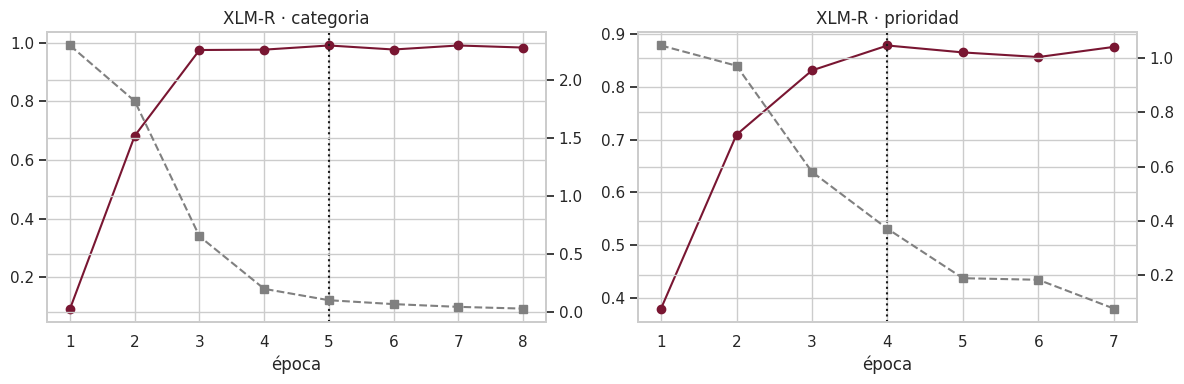

In [8]:
if xlmr:
    fig, ax = plt.subplots(1, len(OBJ), figsize=(12, 4))
    for a, o in zip(np.atleast_1d(ax), OBJ):
        h = pd.DataFrame(xlmr[o]["historia"])
        a.plot(h["epoca"], h["f1_val"], "o-", color=GRANATE, label="F1-macro val")
        a2 = a.twinx(); a2.plot(h["epoca"], h["loss_train"], "s--", color="gray", label="loss train")
        a.axvline(xlmr[o]["mejor_epoca"], ls=":", color="k"); a.set_title(f"XLM-R · {o}"); a.set_xlabel("época")
    guardar_fig("03_xlmr_epocas")

## 3. Comparación en validación

categoria: SVM 0.996 vs XLM-R 0.991 · McNemar p = 1.000
prioridad: SVM 0.863 vs XLM-R 0.879 · McNemar p = 0.424


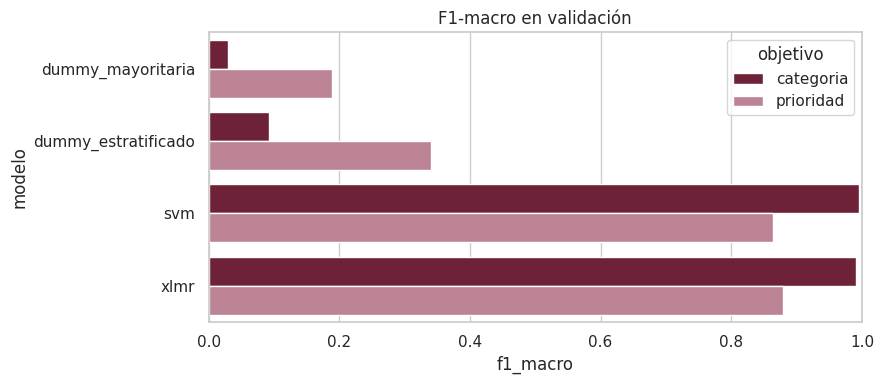

In [9]:
comp = {}
for o in OBJ:
    if "xlmr" in pred_val[o]:
        comp[o] = mcnemar(val[o], pred_val[o]["svm"], pred_val[o]["xlmr"])
        print(f"{o}: SVM {res[o]['svm']['f1_macro']:.3f} vs XLM-R {res[o]['xlmr']['f1_macro']:.3f} · McNemar p = {comp[o]['p']:.3f}")
filas = [{"objetivo": o, "modelo": m, "f1_macro": r["f1_macro"]} for o in OBJ for m, r in res[o].items()]
g = pd.DataFrame(filas)
plt.figure(figsize=(9, 4))
sns.barplot(data=g, x="f1_macro", y="modelo", hue="objetivo", palette=[GRANATE, "#c47a8f"])
plt.title("F1-macro en validación"); plt.xlim(0, 1)
guardar_fig("03_comparacion_validacion")

In [10]:
guardar_json({"metricas_val": res, "mcnemar_val_svm_vs_xlmr": comp,
              "xlmr": {o: {k: v for k, v in xlmr[o].items() if not k.startswith("proba")} for o in xlmr},
              "params_svm": cfg["svm"], "params_xlmr": cfg["xlmr"]}, f"{MET}/03_modelado.json")

PosixPath('/content/drive/MyDrive/triajeia-isp/results/metrics/03_modelado.json')

In [11]:
# Guarda el registro del entorno. En Colab, los resultados ya quedaron en Google Drive
# (MyDrive/triajeia-isp/results y models). Descargue además este notebook con sus salidas:
# Archivo → Descargar → .ipynb, y colóquelo en notebooks/ del repositorio.
guardar_json(entorno(), f"{MET}/entorno_{NB}.json")
print("Listo:", NB)

Listo: 03
